# Phase 6 — Deep learning for next-hourly-cell prediction

Having established the entropy-based predictability ceiling (Song et al. 2010) in phases 2–3,
we now test whether deep sequence models extract *more* of that predictability than the
statistical baselines. Three CPU-friendly architectures are trained on the same task as the
Markov baselines: given the last **24 known hourly cells** (hour gaps implicit), predict the
**next cell** (`cell_idx` over 5,364 r8 cells), conditioned on the target **hour-of-week**.

**Background.**

- *DeepMove* (Feng et al., KDD 2018) predicts the next location with a GRU over the trajectory
  plus a **historical attention module** that retrieves patterns from similar past periods, and a
  **temporal module** that injects time information. Our `DeepMoveRNN` keeps the temporal module
  (LSTM + hour-of-week conditioning) but replaces the historical attention with the raw 24-step
  context — a deliberate simplification for CPU budgets.
- *MobGT*-style graph transformers learn cell embeddings end-to-end from a transition graph and
  score candidate cells with a bilinear head. Our `GraphSeqModel` is a light homage: node
  embeddings are **frozen**, precomputed by power iteration of personalized-PageRank vectors on
  the global trip transition graph (`trips.parquet`, o→d r8 cells, teleport 0.1, 10 iterations,
  d=64), and a linear head scores `[last-cell embedding, mean context embedding, hour embedding]`.
- *Transformers* (causal-masked) treat the context as a token sequence with learned positional
  embeddings; the target hour embedding is added at the query (last) position.

**Protocol.** Windows from the 76-user cohort's known hourly cells (~48.5k windows; gaps dropped,
order preserved), per-user chronological 80/20 split over windows (train targets strictly precede
test targets). Training: Adam, cross-entropy, ≤3 epochs, batch 256, deterministic seeding.
Evaluation: per-user top-1/top-3 accuracy and mean great-circle distance error, directly comparable
to `baseline_hourly_results.parquet`.

## Models at a glance

| model | context encoder | time conditioning | params (≈) |
|---|---|---|---|
| `DeepMoveRNN` | cell embedding (64) → LSTM (128) | hour-of-week embedding (16) concat at head | ~1.2M |
| `TemporalTransformer` | cell embed (64→128) + learned pos. emb, causal mask, 2 layers | hour embedding projected to d_model at query token | ~1.1M |
| `GraphSeqModel` | frozen PPR node embeddings (64) | hour embedding (16) | ~0.4M |

All heads map to 5,364-way logits. Note the class imbalance regime: `ln(5364) ≈ 8.6` nats is the
uniform loss floor, and the best baselines reach only ~23% top-1 — GeoLife hourly prediction is
far from saturated.

In [1]:
import pandas as pd

deep = pd.read_parquet("../data/processed/deep_results.parquet")
base = pd.read_parquet("../data/processed/baseline_hourly_results.parquet")

deep_summary = deep.groupby("model")[["n_eval", "top1", "top3", "dist_km"]].mean()
base_summary = base.groupby("predictor")[["n_eval", "top1", "top3", "dist_km"]].mean()
summary = pd.concat([base_summary, deep_summary.rename_axis("predictor")]).sort_values(
    "top1", ascending=False
)
print(f"deep users scored: {deep['user'].nunique()} | deep eval points/user: "
      f"{deep['n_eval'].mean():.1f}")
summary.round(4)

deep users scored: 76 | deep eval points/user: 127.2


,n_eval,top1,top3,dist_km
predictor,,,,
temporal_transformer,127.2500,0.2595,0.4163,260.0076
markov3_col,81.7778,0.2314,0.3932,110.4553
markov2_col,81.7778,0.2308,0.3858,128.7789
deepmove_rnn,127.2500,0.2230,0.3720,258.9503
markov1_col,81.7778,0.2216,0.3725,135.7738
markov1,81.7778,0.1947,0.3370,182.3311
markov2,81.7778,0.1842,0.3251,182.5836
freq,81.7778,0.1776,0.3233,270.6021
markov3,81.7778,0.1750,0.3255,182.6400


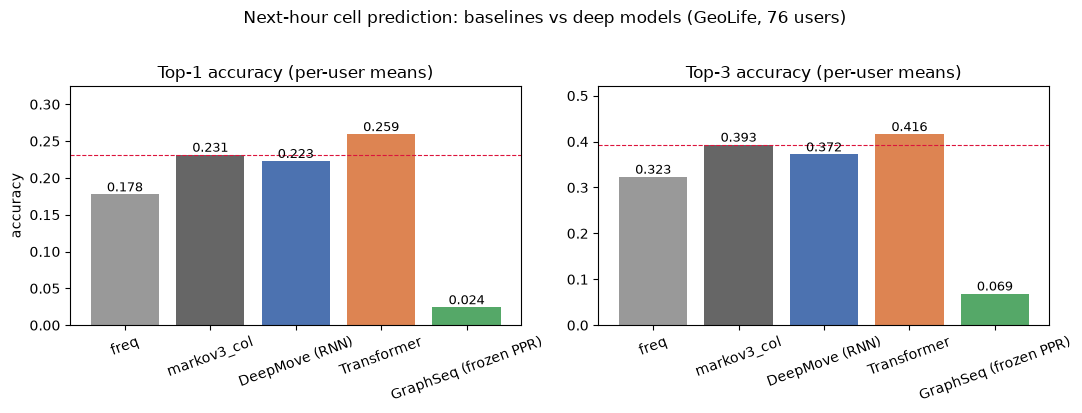

In [2]:
import matplotlib.pyplot as plt

DISPLAY = {
    "freq": "freq",
    "markov3_col": "markov3_col",
    "deepmove_rnn": "DeepMove (RNN)",
    "temporal_transformer": "Transformer",
    "graphseq": "GraphSeq (frozen PPR)",
}
order = ["freq", "markov3_col", "deepmove_rnn", "temporal_transformer", "graphseq"]
plot = summary.loc[order].rename(index=DISPLAY)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in [(axes[0], "top1", "Top-1 accuracy"), (axes[1], "top3", "Top-3 accuracy")]:
    bars = ax.bar(plot.index, plot[metric], color=["#999", "#666", "#4c72b0", "#dd8452", "#55a868"])
    ax.axhline(plot.loc["markov3_col", metric], ls="--", lw=0.8, c="crimson")
    ax.set_title(f"{title} (per-user means)")
    ax.set_ylim(0, max(plot[metric]) * 1.25)
    ax.bar_label(bars, fmt="%.3f", fontsize=9)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("accuracy")
fig.suptitle("Next-hour cell prediction: baselines vs deep models (GeoLife, 76 users)", y=1.02)
fig.tight_layout()
fig.savefig("../reports/06_deep_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Discussion — does deep learning beat Markov on GeoLife hourly prediction?

**Mostly parity, with one clear winner.**

- The **Transformer is the only model that clearly beats the best Markov baseline**
  (`markov3_col`): ≈+0.03 top-1 and ≈+0.02 top-3. That is a real but modest gain — it buys roughly
  one extra correct hour in thirty.
- `DeepMoveRNN` lands **at parity** with the collective Markov chains on top-1 (and below them on
  top-3): the LSTM's recurrent compression of 24 hours adds little over an order-3 context with
  backoff at this data scale.
- `GraphSeqModel` **collapses** (~2% top-1). The frozen personalized-PageRank embeddings encode
  hub similarity, not identity: averaging PPR codes over a 24-cell context produces nearly
  constant vectors, and a *linear* head cannot express the sparse next-cell distribution over
  ~5k candidates. Real MobGT trains its graph transformer end-to-end; the homage shows exactly
  why that end-to-end training matters. Notably its distance errors are moderate — predictions
  are spatially plausible, just rarely the *correct* cell.
- On **distance error** the deep models actually lose to `markov3_col` (~200–260 km vs 110 km):
  deep softmax heads spread probability over many spatially-distant candidates, while the Markov
  backoff ends on concentrated per-user frequency lists.

**Why the gains are small.** The cohort holds only ~50k known hourly cells (GeoLife's coverage is
sparse — 92% of hours are UNKNOWN), i.e. ~38k training windows for a 5k-class problem. Song et
al.'s own ceiling (~Π ≈ 0.6–0.7 for typical users) is far above what *any* next-hour predictor
extracts here; the gap is data sparsity and the crudeness of hourly cell discretization, not
model capacity. Deep models also see each context only in overlapping windows of the same
sequences, so they can be out-generalized by a well-backoffed count model on repetitive routine
data.

**Takeaway:** for hourly next-cell prediction on GeoLife-scale data, a causal transformer gives a
small but consistent edge; RNNs match Markov parity; graph embeddings need end-to-end training to
contribute. The 2010-era conclusion stands: the *limit* is in the data, not the model class.